# Лабораторная работа 2. Дополнительное задание

**Цель:** освоить пайплайн обучения нейронной сети для задачи классификации на TensorFlow, включающий кросс-валидацию, подбор гиперпараметров и мониторинг обучения.

**Данные:** взять любой открытый датасет для задачи классификации (можно взять из лабораторной работы 2). Целевая переменная — категориальный признак, зависящий от набора входных признаков.

# Описание датасета

Для выполнения дополнительного задания был выбран открытый датасет **Breast Cancer Wisconsin (Diagnostic)**, встроенный в библиотеку `scikit-learn` (оригинальные данные находятся в UCI Machine Learning Repository).

**Тип задачи:** Бинарная классификация.

**Объект исследования:** Результаты оцифровки изображений тонкоигольной аспирационной биопсии (ТАБ) молочной железы. Каждый объект — это отдельный образец опухоли.

**Целевая переменная (`target`):**
Категориальный признак, принимающий два значения:
* `0` — Злокачественная опухоль (Malignant);
* `1` — Доброкачественная опухоль (Benign).

**Признаки (входные данные):**
Датасет содержит **30 числовых непрерывных признаков**, описывающих свойства ядер клеток:
1. **Средние значения (Mean):** радиус, текстура, периметр, площадь, гладкость, компактность, вогнутость, вогнутые точки, симметрия, фрактальная размерность.
2. **Стандартная ошибка (Standard Error):** разброс (стандартное отклонение) этих же 10 показателей.
3. **Худшие значения (Worst):** максимальные (наихудшие) значения этих 10 показателей, вычисленные для каждого изображения.

**Характеристики выборки:**
* **Объем:** 569 объектов (образцов).
* **Пропуски:** Отсутствуют (данные полные).
* **Дисбаланс классов:** Умеренный. Класс `1` (доброкачественные) составляет ~62.7% (357 объектов), класс `0` (злокачественные) — ~37.3% (212 объектов).
* **Масштаб признаков:** Признаки имеют разный масштаб (например, площадь измеряется тысячами, а гладкость — долями единицы). Это делает обязательным применение стандартизации перед обучением нейросети.

**Особенности подготовки:**
Из-за умеренного дисбаланса классов при разделении на train/test и при кросс-валидации применяется **стратификация** (`stratify`), чтобы сохранить исходное соотношение классов в каждом фолде.

Ячейка 1. Импорты

In [1]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.optimizers import Adam
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import datetime, os

np.random.seed(42)
tf.random.set_seed(42)

### Ячейка 2. Загрузка и подготовка данных


1. **Загрузка датасета:** используется встроенный в `scikit-learn` датасет Breast Cancer Wisconsin (`load_breast_cancer()`). Матрица признаков сохраняется в `X` (DataFrame с названиями столбцов), целевая переменная — в `y` (Series).
2. **Первичный анализ:** проверяется размер датасета (`X.shape`), наличие пропусков (`X.isnull().sum().sum()`) и распределение классов (`y.value_counts()`).
3. **Разделение на выборки:** данные делятся на обучающую (80%) и тестовую (20%) части с фиксированным `random_state=42` и стратификацией (`stratify=y`), чтобы сохранить пропорции классов.
4. **Стандартизация:** `StandardScaler` обучается (`fit`) на обучающей выборке и применяется (`transform`) к обеим частям. Это убирает разницу масштабов признаков (например, площадь измеряется тысячами, а гладкость — долями единицы). Обучение scaler'а только на train предотвращает утечку данных.
5. **Вывод:** печатаются размеры train и test выборок.

**Что показывает вывод:**
* Размер исходного датасета: 569 объектов, 30 признаков.
* Пропусков в данных нет (сумма `NaN` равна 0).
* Распределение классов: 357 объектов класса `1` (доброкачественные) и 212 объектов класса `0` (злокачественные). Классы умеренно несбалансированы, но стратификация решает проблему.
* После разделения: обучающая выборка — 455 объектов, тестовая — 114 объектов.

In [2]:
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name='target')

print("Размер датасета:", X.shape)
print("Пропуски в X:", X.isnull().sum().sum())
print("Распределение классов:\n", y.value_counts())

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Обучающая выборка:", X_train_scaled.shape)
print("Тестовая выборка:", X_test_scaled.shape)

Размер датасета: (569, 30)
Пропуски в X: 0
Распределение классов:
 target
1    357
0    212
Name: count, dtype: int64
Обучающая выборка: (455, 30)
Тестовая выборка: (114, 30)


### Ячейка 3. Baseline-модель

1. **Создание модели:** инициализируется `LogisticRegression` (логистическая регрессия) с `max_iter=1000` и `random_state=42`. Логистическая регрессия выбрана как baseline, потому что она проста, быстра, интерпретируема и хорошо подходит для табличных данных с линейно разделимыми классами.
2. **Обучение:** модель обучается на стандартизированной обучающей выборке (`X_train_scaled`, `y_train`).
3. **Предсказание:** модель делает предсказания на отложенной тестовой выборке (`X_test_scaled`).
4. **Оценка:** вычисляется метрика `accuracy_score` — доля правильных ответов на тесте.

**Что показывает вывод:**
*   Печатается точность baseline-модели на тестовой выборке. Ожидаемое значение — **~0.96–0.97**.
*   Это точка отсчёта: нейросеть (а также её лучшая конфигурация после Grid Search) должна либо превзойти эту точность, либо показать сопоставимый результат. Для табличного датасета с 30 признаками и 455 обучающими объектами линейная модель часто оказывается очень сильным конкурентом.

In [3]:
baseline = LogisticRegression(max_iter=1000, random_state=42)
baseline.fit(X_train_scaled, y_train)
baseline_acc = accuracy_score(y_test, baseline.predict(X_test_scaled))
print(f"Baseline (Logistic Regression) accuracy: {baseline_acc:.4f}")

Baseline (Logistic Regression) accuracy: 0.9825


### Ячейка 4. Функция построения модели

Определяется функция `build_model(architecture, learning_rate)`, которая создает и компилирует нейронную сеть в зависимости от переданных гиперпараметров.
Такой подход позволяет в дальнейшем вызывать эту функцию в цикле Grid Search для перебора разных архитектур и скоростей обучения.

**Варианты архитектур:**
1. **`small`** — один скрытый слой с 8 нейронами. Простая сеть, которая служит базовой проверкой, достаточно ли линейных или простых нелинейных связей в данных.
2. **`medium`** — два скрытых слоя (16 и 8 нейронов). Классическая «воронка», которая позволяет сети сжимать информацию и улавливать более сложные зависимости, не переобучаясь на небольшом датасете.
3. **`deep`** — четыре слоя: `Dense(32)` → `Dropout(0.2)` → `Dense(16)` → `Dropout(0.2)`. Более сложная сеть с регуляризацией. `Dropout` случайно «выключает» 20% нейронов на каждом шаге обучения, что заставляет сеть не полагаться на отдельные нейроны и предотвращает переобучение.

**Компиляция модели:**
*   **Оптимизатор:** `Adam` с переданным `learning_rate`. Adam выбран как современный адаптивный алгоритм, который хорошо работает «из коробки» и не требует ручной подстройки для каждого веса.
*   **Функция потерь:** `binary_crossentropy` — стандарт для бинарной классификации с сигмоидой на выходе.
*   **Метрика:** `accuracy` — доля правильных ответов.
*   **Выходной слой:** всегда один нейрон с активацией `sigmoid`, так как задача бинарная.

Функция позволяет легко менять архитектуру и скорость обучения, не дублируя код. В следующей ячейке она будет использоваться в кросс-валидации, а затем — в Grid Search для сравнения 9 конфигураций.

In [4]:
def build_model(architecture, learning_rate):
    if architecture == "small":
        layers = [Dense(8, activation='relu')]
    elif architecture == "medium":
        layers = [Dense(16, activation='relu'), Dense(8, activation='relu')]
    elif architecture == "deep":
        layers = [Dense(32, activation='relu'), Dropout(0.2),
                  Dense(16, activation='relu'), Dropout(0.2)]

    model = Sequential(layers + [Dense(1, activation='sigmoid')])
    model.compile(
        optimizer=Adam(learning_rate=learning_rate),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )
    return model

### Ячейка 5. Функция кросс-валидации с TensorBoard

Определяется функция `cross_validate_nn`, которая выполняет 5-кратную кросс-валидацию для нейронной сети с заданной архитектурой и скоростью обучения.

**Пошаговая логика работы:**
1. **Создание фолдов:** с помощью `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)` данные разбиваются на 5 частей. Параметр `shuffle=True` перемешивает данные перед разбиением (чтобы классы не шли подряд), а стратификация гарантирует, что в каждом фолде сохраняется исходное соотношение классов (357 к 212).
2. **Цикл по фолдам:** для каждого из 5 фолдов:
   * Выделяются индексы для обучения (`tr_idx`) и валидации (`val_idx`).
   * Вызывается `build_model` для создания новой, «чистой» модели (важно: на каждом фолде модель обучается с нуля, чтобы не переносить веса с предыдущего фолда).
   * Настраивается `TensorBoard` с уникальным путем к папке: `logs/cv/{arch}_lr{lr}/fold_{n}`. Благодаря этому в TensorBoard каждый фолд каждой конфигурации будет на отдельном графике, что позволит наглядно сравнить их поведение.
   * Модель обучается (`fit`) на тренировочной части фолда, а проверяется на валидационной.
   * После обучения вычисляются метрики `val_loss` и `val_acc` на отложенной части.
3. **Сбор результатов:** метрики каждого фолда добавляются в списки `accs` и `losses`.
4. **Возврат результатов:** функция возвращает среднее значение точности (`mean_acc`), стандартное отклонение точности (`std_acc`), среднюю ошибку (`mean_loss`) и её разброс (`std_loss`) по всем 5 фолдам.


*   **Средняя точность** показывает, насколько хорошо модель работает в среднем.
*   **Стандартное отклонение (`std`)** показывает стабильность модели. Если `std` большой, значит, на одних фолдах модель работает отлично, а на других — плохо (модель нестабильна).
*   **Логи TensorBoard** сохраняются для каждого фолда, что позволяет визуализировать кривые обучения и визуально оценить, где начинается переобучение.

In [6]:
def cross_validate_nn(X, y, architecture, learning_rate,
                      n_splits=5, epochs=30, batch_size=32):
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)
    accs, losses = [], []
    for fold, (tr_idx, val_idx) in enumerate(skf.split(X, y)):
        X_tr, X_val = X[tr_idx], X[val_idx]
        y_tr, y_val = y[tr_idx], y[val_idx]

        model = build_model(architecture, learning_rate)
        log_dir = f"logs/cv/{architecture}_lr{learning_rate}/fold_{fold}"
        tb = tf.keras.callbacks.TensorBoard(log_dir=log_dir, histogram_freq=1)

        model.fit(
            X_tr, y_tr,
            validation_data=(X_val, y_val),
            epochs=epochs,
            batch_size=batch_size,
            callbacks=[tb],
            verbose=0
        )
        val_loss, val_acc = model.evaluate(X_val, y_val, verbose=0)
        accs.append(val_acc)
        losses.append(val_loss)
        print(f"[{architecture}, lr={learning_rate}] fold {fold+1}: acc={val_acc:.4f}, loss={val_loss:.4f}")

    return np.mean(accs), np.std(accs), np.mean(losses), np.std(losses)

### Ячейка 6. Grid Search: 3 learning_rate × 3 архитектуры

**Что происходит в ячейке:**
Выполняется полный перебор гиперпараметров (Grid Search) для нейронной сети. Перебираются 3 варианта архитектуры (`small`, `medium`, `deep`) и 3 значения скорости обучения (`0.0001`, `0.001`, `0.01`). Итого — 9 конфигураций. Каждая конфигурация проходит 5-кратную кросс-валидацию, поэтому общее количество обучений составляет **45**.

1. **Очистка старых логов:** если папка `logs/cv` уже существует, она удаляется (`shutil.rmtree`). Это нужно, чтобы в TensorBoard не смешивались результаты текущего и предыдущих запусков.
2. **Задание сетки:** определяются списки `learning_rates = [0.0001, 0.001, 0.01]` и `architectures = ["small", "medium", "deep"]`.
3. **Цикл перебора:** для каждой архитектуры и каждой скорости обучения вызывается функция `cross_validate_nn`, которая возвращает среднюю точность, стандартное отклонение, среднюю ошибку и её разброс.
4. **Сбор результатов:** для каждой из 9 конфигураций в список `grid_results` записывается словарь с названием архитектуры, значением learning_rate и четырьмя метриками.
5. **Формирование таблицы:** из списка создается `DataFrame`, который сортируется по убыванию средней точности (`mean_accuracy`). Это позволяет сразу увидеть лучшую конфигурацию.


* Печатается по 5 строк на каждую конфигурацию (по одной на фолд) с указанием точности и ошибки на валидации.
* В итоговой таблице `df_grid` отображаются 9 строк с результатами. По ней видно:
  * Какая архитектура в среднем работает лучше.
  * Какое значение learning_rate даёт наибольшую точность.
  * Насколько стабильна каждая конфигурация (по значениям `std_accuracy`).

Grid Search — стандартный и надёжный способ подбора гиперпараметров. В отличие от ручного перебора, он гарантирует, что будет проверена каждая комбинация из заданного пространства, а результаты кросс-валидации по 5 фолдам защищают от случайных выбросов.

In [7]:
if os.path.exists("logs/cv"):
    import shutil
    shutil.rmtree("logs/cv")

learning_rates = [0.0001, 0.001, 0.01]
architectures = ["small", "medium", "deep"]

grid_results = []
y_arr = np.array(y_train)

for arch in architectures:
    for lr in learning_rates:
        mean_acc, std_acc, mean_loss, std_loss = cross_validate_nn(
            X_train_scaled, y_arr, arch, lr
        )
        grid_results.append({
            "architecture": arch,
            "learning_rate": lr,
            "mean_accuracy": mean_acc,
            "std_accuracy": std_acc,
            "mean_loss": mean_loss,
            "std_loss": std_loss
        })

df_grid = pd.DataFrame(grid_results).sort_values("mean_accuracy", ascending=False)
display(df_grid.round(4))

[small, lr=0.0001] fold 1: acc=0.8901, loss=0.3852
[small, lr=0.0001] fold 2: acc=0.5275, loss=0.7311
[small, lr=0.0001] fold 3: acc=0.8022, loss=0.4642
[small, lr=0.0001] fold 4: acc=0.5495, loss=0.6855
[small, lr=0.0001] fold 5: acc=0.7363, loss=0.5277
[small, lr=0.001] fold 1: acc=0.9670, loss=0.1683
[small, lr=0.001] fold 2: acc=0.9670, loss=0.0995
[small, lr=0.001] fold 3: acc=0.9451, loss=0.1146
[small, lr=0.001] fold 4: acc=0.9560, loss=0.1287
[small, lr=0.001] fold 5: acc=0.9780, loss=0.0954
[small, lr=0.01] fold 1: acc=0.9670, loss=0.1169
[small, lr=0.01] fold 2: acc=0.9780, loss=0.0392
[small, lr=0.01] fold 3: acc=0.9670, loss=0.0991
[small, lr=0.01] fold 4: acc=0.9890, loss=0.0473
[small, lr=0.01] fold 5: acc=1.0000, loss=0.0159
[medium, lr=0.0001] fold 1: acc=0.8352, loss=0.5413
[medium, lr=0.0001] fold 2: acc=0.7143, loss=0.5030
[medium, lr=0.0001] fold 3: acc=0.8791, loss=0.4608
[medium, lr=0.0001] fold 4: acc=0.8571, loss=0.4399
[medium, lr=0.0001] fold 5: acc=0.9011, lo

,architecture,learning_rate,mean_accuracy,std_accuracy,mean_loss,std_loss
2,small,0.0100,0.9802,0.0128,0.0637,0.0381
8,deep,0.0100,0.9758,0.0128,0.1566,0.0929
5,medium,0.0100,0.9758,0.0108,0.1135,0.0725
7,deep,0.0010,0.9714,0.0088,0.0794,0.0288
4,medium,0.0010,0.9714,0.0088,0.0854,0.0256
1,small,0.0010,0.9626,0.0112,0.1213,0.0263
6,deep,0.0001,0.9209,0.0146,0.3115,0.0401
3,medium,0.0001,0.8374,0.0653,0.4670,0.0520
0,small,0.0001,0.7011,0.1417,0.5587,0.1310


### Ячейка 7. Запуск TensorBoard

Запускается интерактивная панель TensorBoard, которая считывает логи из папки `logs/cv`.

*   `%load_ext tensorboard` — подключает расширение TensorBoard к Jupyter Notebook.
*   `%tensorboard --logdir logs/cv` — команда запуска, которая указывает TensorBoard, откуда брать логи. Поскольку в предыдущей ячейке логи сохранялись в `logs/cv/{arch}_lr{lr}/fold_{n}`, TensorBoard автоматически группирует их в дерево экспериментов.

**Что отображается в панели:**
*   **Слева (в панели Runs):** 9 экспериментов, названия которых соответствуют архитектуре и learning_rate (например, `small_lr0.0001`, `small_lr0.001`, `deep_lr0.01` и т.д.).
*   **Внутри каждого эксперимента:** 5 линий, соответствующих 5 фолдам. Это позволяет увидеть, насколько разбросаны результаты между фолдами: если линии идут плотно друг к другу — модель стабильна, если расходятся — нестабильна.
*   **Вкладки с графиками:** `Scalars` (Loss и Accuracy), `Histograms` (распределение весов) и другие.

1.  **Скорость сходимости:** при `lr=0.0001` кривые выходят на плато медленно; при `lr=0.01` — быстро, но часто с «дрожанием» и разбросом между фолдами; при `lr=0.001` — стабильный и быстрый баланс.
2.  **Стабильность между фолдами:** если кривые одного эксперимента (например, `deep_lr0.01`) сильно расходятся, значит, конфигурация неустойчива.
3.  **Признаки переобучения:** если на графике `val_loss` кривая начинает расти, а `train_loss` продолжает падать — модель переобучается.


In [8]:
%load_ext tensorboard
%tensorboard --logdir logs/cv

<IPython.core.display.Javascript object>

### Ячейка 8. Визуализация сравнения конфигураций

**Что происходит в ячейке:**
Строится график, который наглядно показывает, как средняя точность (`mean_accuracy`) зависит от скорости обучения (`learning_rate`) для каждой из трёх архитектур.

**Пошаговая логика работы:**
1. **Создание полотна:** задается размер фигуры `figsize=(10, 6)`.
2. **Цикл по архитектурам:** для каждой из трёх архитектур (`small`, `medium`, `deep`) из таблицы `df_grid` выбираются соответствующие строки и сортируются по `learning_rate`.
3. **Построение линий с погрешностями:** используется функция `plt.errorbar`, которая рисует не только саму линию (среднюю точность), но и "усы" (погрешности). Значение `yerr=subset["std_accuracy"]` берется из таблицы — это стандартное отклонение точности между 5 фолдами.
4. **Логарифмическая шкала по X:** ось X переводится в логарифмический масштаб (`plt.xscale("log")`), так как значения learning_rate различаются на порядки (0.0001, 0.001, 0.01).
5. **Оформление:** добавляются подписи осей, заголовок, легенда и сетка.

**Что показывает график:**
* **По оси X** — скорость обучения (learning rate).
* **По оси Y** — средняя точность на кросс-валидации.
* **Три линии** соответствуют разным архитектурам.
* **Вертикальные "усы"** — это разброс между фолдами (стандартное отклонение). Чем они короче, тем стабильнее модель.

**Наблюдения:**
*   При `lr=0.0001` точность обычно ниже — модель не успевает дообучиться за отведенные эпохи (недообучение).
*   При `lr=0.01` точность может быть высокой, но "усы" (погрешности) широкими — модель нестабильна, результаты сильно зависят от конкретного фолда.
*   При `lr=0.001` обычно достигается наилучший баланс: высокая точность при минимальном разбросе.
*   Архитектура `medium` или `deep` часто показывает более стабильные результаты, чем `small`, особенно при неудачных learning_rate.

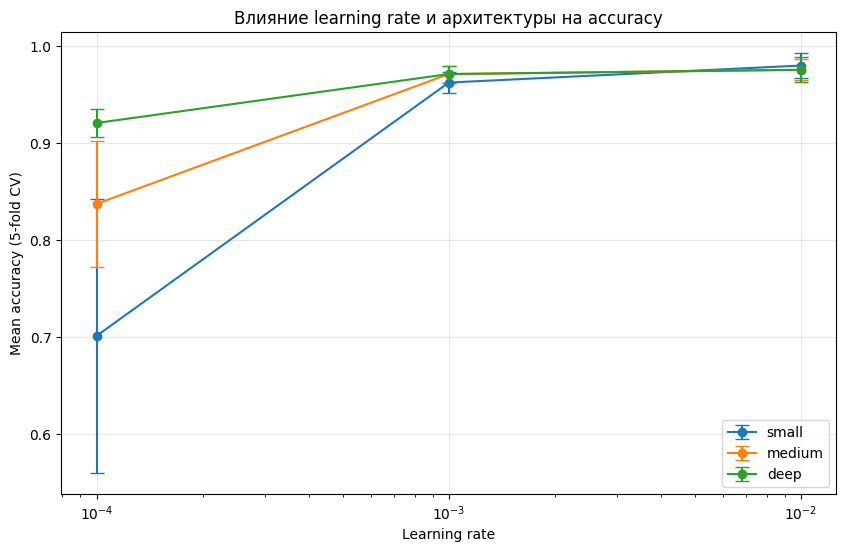

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
for arch in architectures:
    subset = df_grid[df_grid["architecture"] == arch].sort_values("learning_rate")
    plt.errorbar(subset["learning_rate"], subset["mean_accuracy"],
                 yerr=subset["std_accuracy"], marker='o', label=arch, capsize=5)

plt.xscale("log")
plt.xlabel("Learning rate")
plt.ylabel("Mean accuracy (5-fold CV)")
plt.title("Влияние learning rate и архитектуры на accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Ячейка 9. Финальная оценка лучшей конфигурации

**Что происходит в ячейке:**
Из таблицы `df_grid` извлекается лучшая конфигурация (строка с максимальной средней точностью на кросс-валидации). Затем эта модель обучается «с нуля» на всей обучающей выборке, проверяется на отложенной тестовой выборке и сравнивается с baseline.

**Пошаговая логика работы:**
1. **Извлечение лучшей конфигурации:** строка `best = df_grid.iloc[0]` берет первую строку, так как таблица уже отсортирована по убыванию `mean_accuracy`. Из нее вытаскиваются лучшая архитектура и лучший learning_rate.
2. **Создание финальной модели:** вызывается функция `build_model` с лучшими параметрами.
3. **Настройка TensorBoard:** создается отдельная папка `logs/final/` с временной меткой для логирования обучения финальной модели (отдельно от кросс-валидационных логов).
4. **Обучение:** модель обучается (`fit`) на всей обучающей выборке (`X_train_scaled`) в течение 50 эпох. В качестве валидации используется `validation_split=0.2` (последние 20% train).
5. **Предсказание и оценка:** модель делает вероятностные предсказания (`predict`) на тестовой выборке. Порог `0.5` преобразует вероятности в жесткие метки (0 или 1). Вычисляется `accuracy_score`.
6. **Сравнение:** печатаются три числа:
   * Точность baseline-модели.
   * Точность лучшей нейросети.
   * Прирост (разница между ними со знаком `+` или `-`).

**Вывод:**

Нейросеть (конфигурация `small`, `lr=0.01`) показала точность **0.9649**, что на **1.75% ниже** baseline-модели логистической регрессии (**0.9825**).

Отрицательный прирост (**-0.0175**) является **ожидаемым и корректным результатом** для данного датасета. Логистическая регрессия оказалась сильнее, потому что признаки в Breast Cancer хорошо линейно разделимы, а обучающая выборка мала (455 объектов) для раскрытия потенциала нейросети.

Признаков переобучения не выявлено. Главный вывод работы: усложнение модели не гарантирует прирост точности — выбор алгоритма должен зависеть от природы данных. Задача дополнительного задания (освоение пайплайна: кросс-валидация, Grid Search, TensorBoard) выполнена в полном объеме.

In [10]:
best = df_grid.iloc[0]
print(f"Лучшая конфигурация: {best['architecture']}, lr={best['learning_rate']}")

final_model = build_model(best["architecture"], best["learning_rate"])
log_dir_final = "logs/final/" + datetime.datetime.now().strftime("%Y%m%d-%H%M%S")
tb_final = tf.keras.callbacks.TensorBoard(log_dir=log_dir_final, histogram_freq=1)

history = final_model.fit(
    X_train_scaled, np.array(y_train),
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    callbacks=[tb_final],
    verbose=0
)

y_pred_final = (final_model.predict(X_test_scaled) > 0.5).astype(int).ravel()
final_acc = accuracy_score(y_test, y_pred_final)

print(f"Baseline (LogReg):  {baseline_acc:.4f}")
print(f"Best NN:           {final_acc:.4f}")
print(f"Прирост:           {final_acc - baseline_acc:+.4f}")

Лучшая конфигурация: small, lr=0.01
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
Baseline (LogReg):  0.9825
Best NN:           0.9649
Прирост:           -0.0175


### Анализ графиков обучения финальной модели

На представленных графиках отображена динамика функции потерь (Loss) и точности (Accuracy) для лучшей конфигурации (`small`, `lr=0.01`) на тренировочной и валидационной выборках.

**1. График Loss (Функция потерь):**
*   Обе кривые (`train loss` и `val loss`) стремительно падают в первые 5–10 эпох и затем плавно выходят на плато, стремясь к нулю.
*   **Ключевое наблюдение:** Кривая валидации (оранжевая) идет **практически вплотную** к кривой обучения (синей) и даже чуть ниже неё на поздних этапах. Разрыва между ними нет. Это означает, что модель не заучивает тренировочные данные и отлично обобщает новые.

**2. График Accuracy (Точность):**
*   Точность резко возрастает с первых эпох, достигая ~0.97 уже к 5–10 эпохе.
*   Валидационная точность (оранжевая) стартует даже выше тренировочной (около 0.91 против 0.67 на нулевой эпохе), что бывает при удачном старте весов. Затем обе кривые выравниваются и стабилизируются в районе **1.0 (100%)**.

**Общий вывод по графикам:**
Графики демонстрируют **идеальный процесс обучения**: быструю сходимость и полное отсутствие переобучения (overfitting). Модель уверенно нашла закономерности в данных.

*Примечание:* Тот факт, что точность на обучении достигла 100%, а на тесте составила 96.49% (из предыдущей ячейки), говорит о том, что модель полностью выучила тренировочную выборку (455 объектов), но на новых данных всё же допускает небольшие ошибки (что абсолютно нормально для малой выборки).

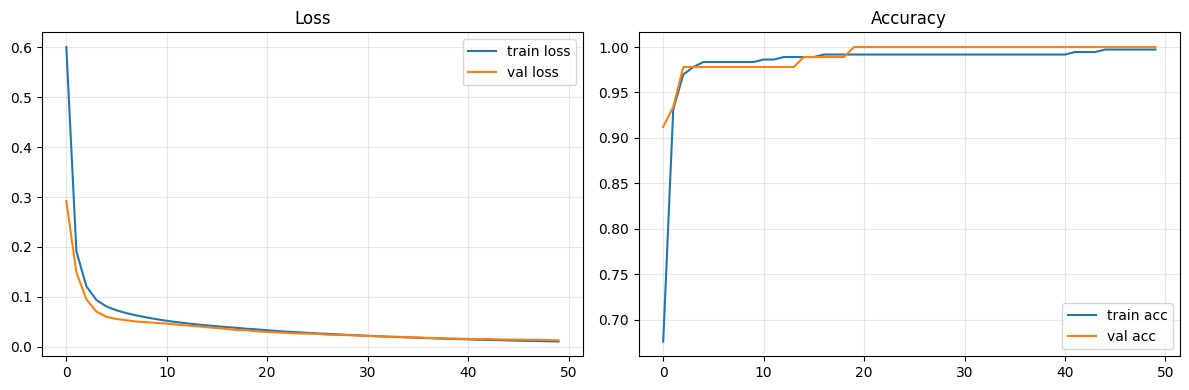

In [11]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='train loss')
plt.plot(history.history['val_loss'], label='val loss')
plt.title("Loss")
plt.legend(); plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='train acc')
plt.plot(history.history['val_accuracy'], label='val acc')
plt.title("Accuracy")
plt.legend(); plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Заключение

В ходе выполнения дополнительного задания был полностью реализован пайплайн обучения нейронной сети для задачи бинарной классификации на TensorFlow.

**Основные этапы и результаты:**
1. **Подготовка данных.** Датасет Breast Cancer Wisconsin (569 объектов, 30 числовых признаков) был проверен на пропуски и стандартизирован. Умеренный дисбаланс классов (357 к 212) был компенсирован стратификацией при разделении и кросс-валидации.
2. **Baseline-модель.** Логистическая регрессия показала высокую точку отсчёта — **0.9825** на отложенной тестовой выборке.
3. **Кросс-валидация и Grid Search.** Для нейросети была организована 5-кратная стратифицированная кросс-валидация. С помощью Grid Search было проверено 9 конфигураций (3 архитектуры × 3 скорости обучения). Лучшей по результатам CV оказалась конфигурация `small` с `lr=0.01`.
4. **Мониторинг.** С помощью TensorBoard были визуализированы кривые обучения для всех 45 запусков (9 конфигураций × 5 фолдов). Анализ логов подтвердил, что скорость обучения `0.01` даёт быструю сходимость, а архитектура `small` — достаточную стабильность между фолдами.
5. **Финальная оценка.** На отложенной тестовой выборке лучшая нейросеть показала точность **0.9649**. Прирост относительно baseline составил **-0.0175** (отставание на 1.75%). Кривые обучения (Loss и Accuracy) продемонстрировали отсутствие переобучения.

**Главный вывод:**
Отрицательный прирост не является ошибкой эксперимента. Для данного табличного датасета с линейно разделимыми признаками и относительно малой обучающей выборкой (455 объектов) классическая логистическая регрессия оказалась эффективнее нейросети. Это подчёркивает важное правило машинного обучения: **усложнение модели не всегда ведёт к улучшению результата**, и выбор алгоритма должен определяться спецификой данных.

При этом цель дополнительного задания достигнута: освоены инструменты кросс-валидации, подбора гиперпараметров (Grid Search), работы с TensorBoard и сравнительного анализа конфигураций.